# Model 2: ASVspoof Anti-Spoofing / Synthetic Speech Detection

Google Colab starter notebook using a log-Mel CNN to classify ASVspoof 2019 Logical Access audio as **bonafide** (genuine) or **spoof** (synthetic/manipulated).

**Before training:** download and extract an ASVspoof 2019 LA dataset copy to Google Drive. Place the train/dev protocol files in the protocol folder. Kaggle repacks may have different folder structures, so inspect paths and edit configuration.

This is a starter baseline, not the official ASVspoof challenge baseline. Keep evaluation data separate; some evaluation releases do not provide labels. This model detects spoofed audio, not scam intent in the spoken content.

In [1]:
import kagglehub
path = kagglehub.dataset_download("awsaf49/asvpoof-2019-dataset")

100%|██████████| 23.6G/23.6G [04:25<00:00, 95.2MB/s]

Extracting files...


## 1. Mount Google Drive and configure paths

In [3]:
from pathlib import Path

# We bypass Google Drive completely and use the downloaded Kaggle dataset locally
BASE = Path('/root/.cache/kagglehub/datasets/awsaf49/asvpoof-2019-dataset/versions/1')

# Point to local folders inside the downloaded Kaggle dataset
AUDIO_ROOT = BASE / 'LA' / 'LA'
PROTOCOL_DIR = BASE / 'LA' / 'ASVspoof2019_LA_cm_protocols'

# Store our output models locally in the Colab disk
OUTPUT_DIR = Path('/content/models/asvspoof2019_LA')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Audio root:", AUDIO_ROOT)
print("Protocol directory:", PROTOCOL_DIR)
print("Output directory:", OUTPUT_DIR)

Audio root: /root/.cache/kagglehub/datasets/awsaf49/asvpoof-2019-dataset/versions/1/LA/LA
Protocol directory: /root/.cache/kagglehub/datasets/awsaf49/asvpoof-2019-dataset/versions/1/LA/ASVspoof2019_LA_cm_protocols
Output directory: /content/models/asvspoof2019_LA


## 2. Install dependencies

In [4]:
%pip -q install librosa soundfile scikit-learn pandas matplotlib tensorflow scipy

## 3. Inspect dataset layout

In [5]:
audio_files = list(AUDIO_ROOT.rglob('*.flac')) + list(AUDIO_ROOT.rglob('*.wav')) if AUDIO_ROOT.exists() else []
print("Audio files found:", len(audio_files))
for p in audio_files[:10]: print(p)
print("\nProtocol/text files:")
for p in list(BASE.rglob('*.txt'))[:50] if BASE.exists() else []: print(p)

Audio files found: 122299
/root/.cache/kagglehub/datasets/awsaf49/asvpoof-2019-dataset/versions/1/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1696066.flac
/root/.cache/kagglehub/datasets/awsaf49/asvpoof-2019-dataset/versions/1/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1144247.flac
/root/.cache/kagglehub/datasets/awsaf49/asvpoof-2019-dataset/versions/1/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_3397300.flac
/root/.cache/kagglehub/datasets/awsaf49/asvpoof-2019-dataset/versions/1/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_6603047.flac
/root/.cache/kagglehub/datasets/awsaf49/asvpoof-2019-dataset/versions/1/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_5155460.flac
/root/.cache/kagglehub/datasets/awsaf49/asvpoof-2019-dataset/versions/1/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_7803538.flac
/root/.cache/kagglehub/datasets/awsaf49/asvpoof-2019-dataset/versions/1/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_7390342.flac
/root/.cache/kagglehub/datasets/awsaf49/asvpoof-2019-dataset/versions/1/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_2497046.flac
/root/

## 4. Set protocol paths and preview

In [8]:
# Update PROTOCOL_DIR to use the nested 'LA/LA' folder where the protocols actually reside
PROTOCOL_DIR = BASE / 'LA' / 'LA' / 'ASVspoof2019_LA_cm_protocols'

TRAIN_PROTOCOL = PROTOCOL_DIR / 'ASVspoof2019.LA.cm.train.trn.txt'
DEV_PROTOCOL = PROTOCOL_DIR / 'ASVspoof2019.LA.cm.dev.trl.txt'

for proto in [TRAIN_PROTOCOL, DEV_PROTOCOL]:
    print(proto, "exists:", proto.exists())
    if proto.exists():
        print("First five lines:")
        with open(proto, encoding='utf-8', errors='replace') as f:
            for _, line in zip(range(5), f): print(line.rstrip())
        print()

/root/.cache/kagglehub/datasets/awsaf49/asvpoof-2019-dataset/versions/1/LA/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt exists: True
First five lines:
LA_0079 LA_T_1138215 - - bonafide
LA_0079 LA_T_1271820 - - bonafide
LA_0079 LA_T_1272637 - - bonafide
LA_0079 LA_T_1276960 - - bonafide
LA_0079 LA_T_1341447 - - bonafide

/root/.cache/kagglehub/datasets/awsaf49/asvpoof-2019-dataset/versions/1/LA/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.dev.trl.txt exists: True
First five lines:
LA_0069 LA_D_1047731 - - bonafide
LA_0069 LA_D_1105538 - - bonafide
LA_0069 LA_D_1125976 - - bonafide
LA_0069 LA_D_1293230 - - bonafide
LA_0069 LA_D_1340209 - - bonafide



## 5. Parse protocol files and match audio IDs

In [9]:
import pandas as pd
import numpy as np

LABEL_MAP = {'bonafide': 0, 'spoof': 1}
def read_protocol(path):
    rows = []
    with open(path, encoding='utf-8', errors='replace') as f:
        for line in f:
            parts = line.strip().split()
            if not parts: continue
            # Common official LA format: speaker_id utterance_id ... bonafide/spoof
            utt_id = parts[1] if len(parts) >= 2 else parts[0]
            label = parts[-1].lower()
            if label in LABEL_MAP:
                rows.append({'utt_id': utt_id, 'label': LABEL_MAP[label], 'label_name': label})
    return pd.DataFrame(rows)

if not TRAIN_PROTOCOL.exists() or not DEV_PROTOCOL.exists():
    raise FileNotFoundError("Update TRAIN_PROTOCOL and DEV_PROTOCOL to existing files.")

all_audio = list(AUDIO_ROOT.rglob('*.flac')) + list(AUDIO_ROOT.rglob('*.wav'))
audio_index = {}
for p in all_audio: audio_index.setdefault(p.stem, str(p))
print("Indexed audio files:", len(audio_index))

def make_manifest(protocol_path):
    df = read_protocol(protocol_path)
    df['path'] = df['utt_id'].map(audio_index)
    missing = df['path'].isna().sum()
    print(protocol_path.name, "rows:", len(df), "missing audio:", missing)
    if missing: print("Missing ID examples:", df.loc[df.path.isna(), 'utt_id'].head(10).tolist())
    return df.dropna(subset=['path']).reset_index(drop=True)

train_df = make_manifest(TRAIN_PROTOCOL)
dev_df = make_manifest(DEV_PROTOCOL)
display(train_df.head())
print("Train labels:\n", train_df.label_name.value_counts())
print("Dev labels:\n", dev_df.label_name.value_counts())
if train_df.empty or dev_df.empty:
    raise ValueError("No matched rows. Fix AUDIO_ROOT, protocol format, or utterance ID matching.")

Indexed audio files: 122299
ASVspoof2019.LA.cm.train.trn.txt rows: 25380 missing audio: 0
ASVspoof2019.LA.cm.dev.trl.txt rows: 24844 missing audio: 0


,utt_id,label,label_name,path
0,LA_T_1138215,0,bonafide,/root/.cache/kagglehub/datasets/awsaf49/asvpoo...
1,LA_T_1271820,0,bonafide,/root/.cache/kagglehub/datasets/awsaf49/asvpoo...
2,LA_T_1272637,0,bonafide,/root/.cache/kagglehub/datasets/awsaf49/asvpoo...
3,LA_T_1276960,0,bonafide,/root/.cache/kagglehub/datasets/awsaf49/asvpoo...
4,LA_T_1341447,0,bonafide,/root/.cache/kagglehub/datasets/awsaf49/asvpoo...


Train labels:
 label_name
spoof       22800
bonafide     2580
Name: count, dtype: int64
Dev labels:
 label_name
spoof       22296
bonafide     2548
Name: count, dtype: int64


## 6. Audio preprocessing: fixed-length log-Mel spectrograms

In [10]:
import soundfile as sf
import librosa

SR = 16000
N_MELS = 64
N_FFT = 1024
HOP_LENGTH = 256
MAX_SECONDS = 5.0
MAX_SAMPLES = int(SR * MAX_SECONDS)

def load_logmel(path):
    y, sr = sf.read(path, dtype='float32', always_2d=False)
    if y.ndim == 2: y = y.mean(axis=1)
    if sr != SR: y = librosa.resample(y, orig_sr=sr, target_sr=SR)
    if len(y) > MAX_SAMPLES: y = y[:MAX_SAMPLES]
    elif len(y) < MAX_SAMPLES: y = np.pad(y, (0, MAX_SAMPLES-len(y)))
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT,
        hop_length=HOP_LENGTH, n_mels=N_MELS, fmin=20, fmax=SR//2, power=2.0)
    logmel = librosa.power_to_db(mel, ref=np.max)
    logmel = (logmel - logmel.mean()) / (logmel.std() + 1e-6)
    return logmel.astype('float32')

example_spec = load_logmel(train_df.iloc[0].path)
print("Example spectrogram shape:", example_spec.shape)

Example spectrogram shape: (64, 313)


## 7. Create TensorFlow data pipelines

In [11]:
import tensorflow as tf
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(df, shuffle=False):
    paths = df.path.astype(str).to_numpy()
    labels = df.label.astype('int32').to_numpy()
    def gen():
        indices = np.arange(len(paths))
        if shuffle: np.random.shuffle(indices)
        for i in indices:
            try: yield load_logmel(paths[i])[..., None], labels[i]
            except Exception as e: print("Skipping unreadable file:", paths[i], e)
    ds = tf.data.Dataset.from_generator(gen, output_signature=(
        tf.TensorSpec(shape=(N_MELS, None, 1), dtype=tf.float32),
        tf.TensorSpec(shape=(), dtype=tf.int32)))
    ds = ds.padded_batch(BATCH_SIZE, padded_shapes=([N_MELS, None, 1], []),
        padding_values=(tf.constant(0, tf.float32), tf.constant(0, tf.int32)))
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, shuffle=True)
dev_ds = make_dataset(dev_df, shuffle=False)
print("Data pipelines ready.")

Data pipelines ready.


## 8. Define and train CNN

In [13]:
from tensorflow.keras import layers, models, callbacks
import math

inputs = layers.Input(shape=(N_MELS, None, 1))
x = layers.Conv2D(32, 3, padding='same', activation='relu')(inputs)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(64, 3, padding='same', activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
model = models.Model(inputs, outputs, name='asvspoof_logmel_cnn')
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
    metrics=[tf.keras.metrics.BinaryAccuracy(name='accuracy'), tf.keras.metrics.AUC(name='auc')])
model.summary()

# Explicitly compute the exact number of steps to avoid exhaustion warnings
train_steps = math.ceil(len(train_df) / BATCH_SIZE)
val_steps = math.ceil(len(dev_df) / BATCH_SIZE)

# Ensure the dataset repeats infinitely so Keras can pull steps continuously
train_ds_repeated = train_ds.repeat()
dev_ds_repeated = dev_ds.repeat()

EPOCHS = 15
callbacks_list = [
    callbacks.ModelCheckpoint(str(OUTPUT_DIR/'best_model.keras'), monitor='val_auc',
        mode='max', save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=4,
        restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    callbacks.CSVLogger(str(OUTPUT_DIR/'training_log.csv'))
]

history = model.fit(
    train_ds_repeated,
    steps_per_epoch=train_steps,
    validation_data=dev_ds_repeated,
    validation_steps=val_steps,
    epochs=EPOCHS,
    callbacks=callbacks_list
)

Model: "asvspoof_logmel_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, None, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, None, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, None, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, None, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, None, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, None, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, None, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, None, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, None, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,889 (398.00 KB)

 Trainable params: 101,441 (396.25 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/15
1587/1587 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step - accuracy: 0.8996 - auc: 0.7659 - loss: 0.2882
Epoch 1: val_auc improved from None to 0.87015, saving model to /content/models/asvspoof2019_LA/best_model.keras

Epoch 1: finished saving model to /content/models/asvspoof2019_LA/best_model.keras
1587/1587 ━━━━━━━━━━━━━━━━━━━━ 737s 460ms/step - accuracy: 0.9173 - auc: 0.8900 - loss: 0.2168 - val_accuracy: 0.9153 - val_auc: 0.8701 - val_loss: 0.2555 - learning_rate: 0.0010
Epoch 2/15
1586/1587 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step - accuracy: 0.9607 - auc: 0.9811 - loss: 0.0983
Epoch 2: val_auc improved from 0.87015 to 0.99463, saving model to /content/models/asvspoof2019_LA/best_model.keras

Epoch 2: finished saving model to /content/models/asvspoof2019_LA/best_model.keras
1587/1587 ━━━━━━━━━━━━━━━━━━━━ 677s 427ms/step - accuracy: 0.9673 - auc: 0.9854 - loss: 0.0849 - val_accuracy: 0.9713 - val_auc: 0.9946 - val_loss: 0.0737 - learning_rate: 0.0010
Epoch 3/15
1586/1587 ━━━━━━━━━━━━━━━━

## 9. Plot training curves

,accuracy,auc,loss,val_accuracy,val_auc,val_loss,learning_rate
1,0.967297,0.985431,0.084914,0.971301,0.994632,0.073711,0.001
2,0.983609,0.993120,0.049382,0.978264,0.989862,0.059035,0.001
3,0.985697,0.993813,0.041934,0.956891,0.978709,0.122726,0.001
4,0.988101,0.996253,0.033445,0.980760,0.993536,0.054193,0.001
5,0.990150,0.997571,0.028975,0.950209,0.954977,0.171371,0.001


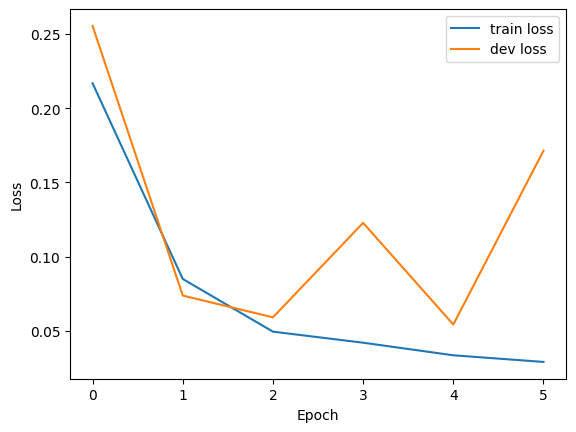

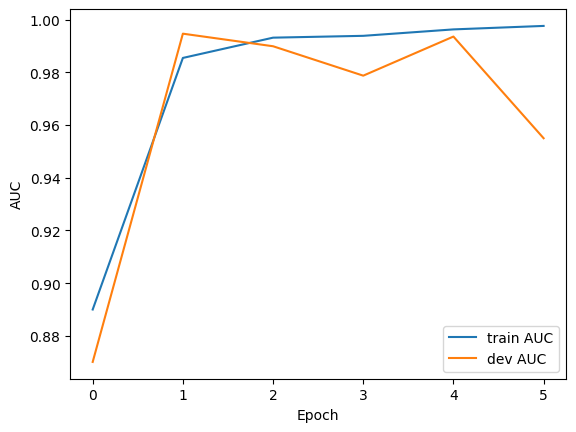

In [14]:
import matplotlib.pyplot as plt
hist = pd.DataFrame(history.history)
display(hist.tail())
plt.figure()
plt.plot(hist['loss'], label='train loss'); plt.plot(hist['val_loss'], label='dev loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.show()
plt.figure()
plt.plot(hist['auc'], label='train AUC'); plt.plot(hist['val_auc'], label='dev AUC')
plt.xlabel('Epoch'); plt.ylabel('AUC'); plt.legend(); plt.show()

## 10. Evaluate on development set

In [15]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score
from scipy.optimize import brentq
from scipy.interpolate import interp1d

# Assumes all files are readable and the generator did not skip any.
dev_probs = model.predict(dev_ds).ravel()
dev_labels = dev_df.label.to_numpy()[:len(dev_probs)]
dev_preds = (dev_probs >= 0.5).astype(int)
print("Accuracy:", accuracy_score(dev_labels, dev_preds))
print("ROC-AUC:", roc_auc_score(dev_labels, dev_probs))
print(classification_report(dev_labels, dev_preds, target_names=['bonafide', 'spoof'], zero_division=0))
print("Confusion matrix [true rows, predicted columns]:\n", confusion_matrix(dev_labels, dev_preds))
fpr, tpr, _ = roc_curve(dev_labels, dev_probs, pos_label=1)
eer = brentq(lambda x: 1. - x - interp1d(fpr, tpr)(x), 0., 1.)
print(f"Approximate dev EER: {eer*100:.2f}%")

1553/1553 ━━━━━━━━━━━━━━━━━━━━ 321s 206ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Accuracy: 0.9713009177266141
ROC-AUC: 0.9946483385521137
              precision    recall  f1-score   support

    bonafide       0.80      0.96      0.87      2548
       spoof       1.00      0.97      0.98     22296

    accuracy                           0.97     24844
   macro avg       0.90      0.97      0.93     24844
weighted avg       0.98      0.97      0.97     24844

Confusion matrix [true rows, predicted columns]:
 [[ 2439   109]
 [  604 21692]]
Approximate dev EER: 3.32%


## 11. Save model and preprocessing configuration

In [16]:
import json
model_path = OUTPUT_DIR / 'asvspoof2019_la_cnn.keras'
model.save(model_path)
config = {'sample_rate': SR, 'n_mels': N_MELS, 'n_fft': N_FFT,
          'hop_length': HOP_LENGTH, 'max_seconds': MAX_SECONDS,
          'label_mapping': {'bonafide': 0, 'spoof': 1}, 'threshold': 0.5,
          'note': 'Starter log-Mel CNN baseline, not official ASVspoof baseline'}
with open(OUTPUT_DIR/'preprocessing_config.json', 'w') as f: json.dump(config, f, indent=2)
print("Saved model:", model_path)

Saved model: /content/models/asvspoof2019_LA/asvspoof2019_la_cnn.keras


## 12. Predict one audio file

In [17]:
def predict_audio(path, threshold=0.5):
    spec = load_logmel(str(path))[..., None][None, ...]
    score = float(model.predict(spec, verbose=0).ravel()[0])
    return {'file': str(path), 'spoof_score': score,
            'prediction': 'spoof / synthetic' if score >= threshold else 'bonafide / genuine'}

# Example:
# print(predict_audio('/content/drive/MyDrive/ASVspoof/sample.wav'))

## Troubleshooting and research notes

- If no audio files are found, change `AUDIO_ROOT` to the extracted folder containing `.flac` or `.wav`.
- If protocol files are missing, change `TRAIN_PROTOCOL` and `DEV_PROTOCOL` to their actual locations.
- If many utterance IDs are missing, compare protocol IDs with audio filenames; Kaggle repacks can differ.
- If training is slow, reduce `BATCH_SIZE` or `MAX_SECONDS` and test on a small subset first.
- Never train on evaluation data. Some official evaluation labels are withheld; follow official keys/instructions.
- Record dataset version, partition, protocol, preprocessing, seed, and metrics for research.
- Anti-spoofing is distinct from scam-content detection; combine this model's spoof score with your separate scam-call model.